# Kalman filter: Brent and WTI Managed Money against trend signals

## 1. Data

Weekly, in thousand contracts, with the model fitted from 2011-01-11 to 2026-08-25. Positions are futures only.

- $y^m_t$: change in Managed Money (MM) net position in market $m$, for $m\in\{B,W\}$ (Brent, WTI).
- $x^m_t$: signal flow implied by the SG Trend replication (Kestner, 2020), which uses prices only. With implied position $P_t=u_th_t$, risk weight $u$ and sizing $h$, $x_t=\Delta u_t\,h_{t-1}$.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "working_ideas" else Path.cwd()
sys.path[:0] = [str(REPO_ROOT / "paper_replication" / "src"), str(REPO_ROOT / "working_ideas" / "src")]
import commodity_trend as ct
import kalman as kl

OUTPUT = REPO_ROOT / "paper_replication" / "outputs" / "kalman_filter"
OUTPUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", lambda v: f"{v:,.3f}")
BRENT, WTI, ZERO_COLOR, WAR_SHADE = "#277f8e", "#b7782c", "#8a8a8a", "#f3e6d8"
WAR, END = pd.Timestamp("2026-03-03"), pd.Timestamp("2026-08-25")

In [2]:
T = ct.trend_panel(REPO_ROOT / "working_ideas" / "data_required", REPO_ROOT / "paper_replication" / "data_required",
                   "2026-08-25")
d_mm, flow = T.d_mm / 1e3, T.signal_flow / 1e3
print(f"Weeks in the panel: {len(d_mm)}, {d_mm.index[0]:%Y-%m-%d} to {d_mm.index[-1]:%Y-%m-%d}")

Weeks in the panel: 921, 2009-01-06 to 2026-08-25


## 2. Steps

**Problem statement.** How closely does Managed Money follow trend signals in Brent and in WTI, how has that changed over time, and when did the two markets diverge? We let the link between MM changes and signal flow vary week by week, instead of assuming one fixed relationship.

**Step 1. Set up the model.** $\beta^m_t$ is the MM contracts traded per contract of signal flow, and it follows a random walk:

$$\begin{pmatrix}y^B_t\\y^W_t\end{pmatrix}=\begin{pmatrix}x^B_t\beta^B_t\\x^W_t\beta^W_t\end{pmatrix}+e_t,\qquad \beta_{t+1}=\beta_t+\eta_t,\qquad e_t\sim N(0,R),\quad \eta_t\sim N(0,Q),$$

with full $2\times2$ $R$ and $Q$, and correlations $\rho_R$ and $\rho_Q$.

**Step 2. Run the filter forward each week.** $\beta_{t\mid s}$ is the estimate of $\beta_t$ given data up to week $s$, and $P_{t\mid s}$ is its variance. Written for one market (for two, $\beta$ is a vector and $P$, $F$, $R$, $Q$ are matrices):

1. Predict the state: $\beta_{t\mid t-1}=\beta_{t-1\mid t-1}$ and $P_{t\mid t-1}=P_{t-1\mid t-1}+Q$.
2. Predict the observation: $\hat y_t=x_t\,\beta_{t\mid t-1}$.
3. Compute the surprise: $v_t=y_t-\hat y_t$, with variance $F_t=x_t^2P_{t\mid t-1}+R$.
4. Compute the gain: $K_t=P_{t\mid t-1}\,x_t/F_t$.
5. Update: $\beta_{t\mid t}=\beta_{t\mid t-1}+K_tv_t$ and $P_{t\mid t}=(1-K_tx_t)\,P_{t\mid t-1}$.

If $x_t=0$, then $K_t=0$: $\beta$ does not move and $P$ grows by $Q$.

**Step 3. Estimate $R$ and $Q$, then smooth.** Maximize the log-likelihood, $-\frac12\sum_t(\log F_t+v_t^2/F_t)$ up to a constant, from three starting values, using the full sample. A backward pass from week $T$ then gives the smoothed $\beta_{t\mid T}$. The table compares the fit with $\rho_Q$ fixed at $-0.5$, 0 and 0.5 by likelihood ratio.

In [3]:
def bivariate_data(x_brent, x_wti, start="2011-01-11"):
    data = pd.concat([d_mm["BRENT"], d_mm["WTI"], x_brent, x_wti], axis=1, keys=["yB", "yW", "xB", "xW"]).loc[start:]
    yB, yW = np.where(data["xB"].isna(), np.nan, data["yB"]), np.where(data["xW"].isna(), np.nan, data["yW"])
    return data.index, yB, yW, data["xB"].fillna(0).to_numpy(), data["xW"].fillna(0).to_numpy()


def starting_values(yB, yW, xB, xW):
    mB, mW = kl.uni_mle(yB, xB), kl.uni_mle(yW, xW)
    bB, bW = np.nansum(xB * yB) / np.nansum(xB[np.isfinite(yB)] ** 2), np.nansum(xW * yW) / np.nansum(xW[np.isfinite(yW)] ** 2)
    eB, eW = yB - bB * xB, yW - bW * xW
    both = np.isfinite(eB) & np.isfinite(eW)
    rho = np.corrcoef(eB[both], eW[both])[0, 1]
    return [np.array([np.log(mB["R"]), np.log(mW["R"]), np.arctanh(rho), np.log(max(mB["Q"], 1e-6)), np.log(max(mW["Q"], 1e-6)),
                      np.arctanh(rho_q)]) for rho_q in (0.0, -0.5, 0.5)]


def fit_bivariate(x_brent, x_wti, start="2011-01-11"):
    """Maximum likelihood, filter and smoother."""
    index, yB, yW, xB, xW = bivariate_data(x_brent, x_wti, start)
    fit = kl.bi_mle(yB, yW, xB, xW, starting_values(yB, yW, xB, xW))
    filtered, smoothed = kl.bi_run(yB, yW, xB, xW, fit["R"], fit["Q"])
    paths = pd.DataFrame({"beta_B_f": filtered["a_filt"][:, 0], "beta_W_f": filtered["a_filt"][:, 1],
                          "beta_B_s": smoothed["a_s"][:, 0], "beta_W_s": smoothed["a_s"][:, 1],
                          "sd_B_f": np.sqrt(filtered["P_filt"][:, 0, 0]), "sd_W_f": np.sqrt(filtered["P_filt"][:, 1, 1]),
                          "sd_B_s": np.sqrt(smoothed["P_s"][:, 0, 0]), "sd_W_s": np.sqrt(smoothed["P_s"][:, 1, 1]),
                          "tilt_f": [kl.tilt(a, P)[0] for a, P in zip(filtered["a_filt"], filtered["P_filt"])],
                          "tilt_s": [kl.tilt(a, P)[0] for a, P in zip(smoothed["a_s"], smoothed["P_s"])]}, index=index)
    paths["sd_spread_s"] = [kl.tilt(a, P)[2] for a, P in zip(smoothed["a_s"], smoothed["P_s"])]
    return dict(fit=fit, filtered=filtered, smoothed=smoothed, paths=paths, data=(index, yB, yW, xB, xW))


base = fit_bivariate(flow["BRENT"], flow["WTI"])
fit = base["fit"]
index, yB, yW, xB, xW = base["data"]


def profile_rho_q(rho_q):
    def nll(th):
        q1, q2 = np.exp(th[3]), np.exp(th[4])
        return -kl.bi_ll(yB.tolist(), yW.tolist(), xB.tolist(), xW.tolist(), np.exp(th[0]), np.exp(th[1]),
                         np.tanh(th[2]) * np.exp(0.5 * (th[0] + th[1])), q1, q2, rho_q * np.sqrt(q1 * q2))
    best = optimize.minimize(nll, fit["theta"][:5], method="Nelder-Mead", options=dict(maxiter=1500, xatol=2e-3, fatol=1e-3, adaptive=True))
    return 2 * (fit["ll"] + best.fun)


print(f"Noise correlation rho_R {fit['rho_R']:.3f}; drift correlation rho_Q {fit['rho_Q']:.3f}; "
      f"SD of beta per year: Brent {np.sqrt(52 * fit['Q'][0, 0]):.3f}, WTI {np.sqrt(52 * fit['Q'][1, 1]):.3f}")
pd.Series({rho: profile_rho_q(rho) for rho in (-0.5, 0.0, 0.5)}, name="LR against the MLE (5% cut-off 3.84)").rename_axis("rho_Q").to_frame()

Noise correlation rho_R 0.312; drift correlation rho_Q 0.908; SD of beta per year: Brent 0.064, WTI 0.099


,LR against the MLE (5% cut-off 3.84)
rho_Q,
-0.500,7.940
0.000,4.583
0.500,1.988


**Step 4. Compare the two betas.** Tilt is $P(\beta^B_t>\beta^W_t\mid\text{data})$, computed from the mean and variance of $\beta^B_t-\beta^W_t$. We record the first week from which it stays above 0.95, for the filtered and smoothed paths.

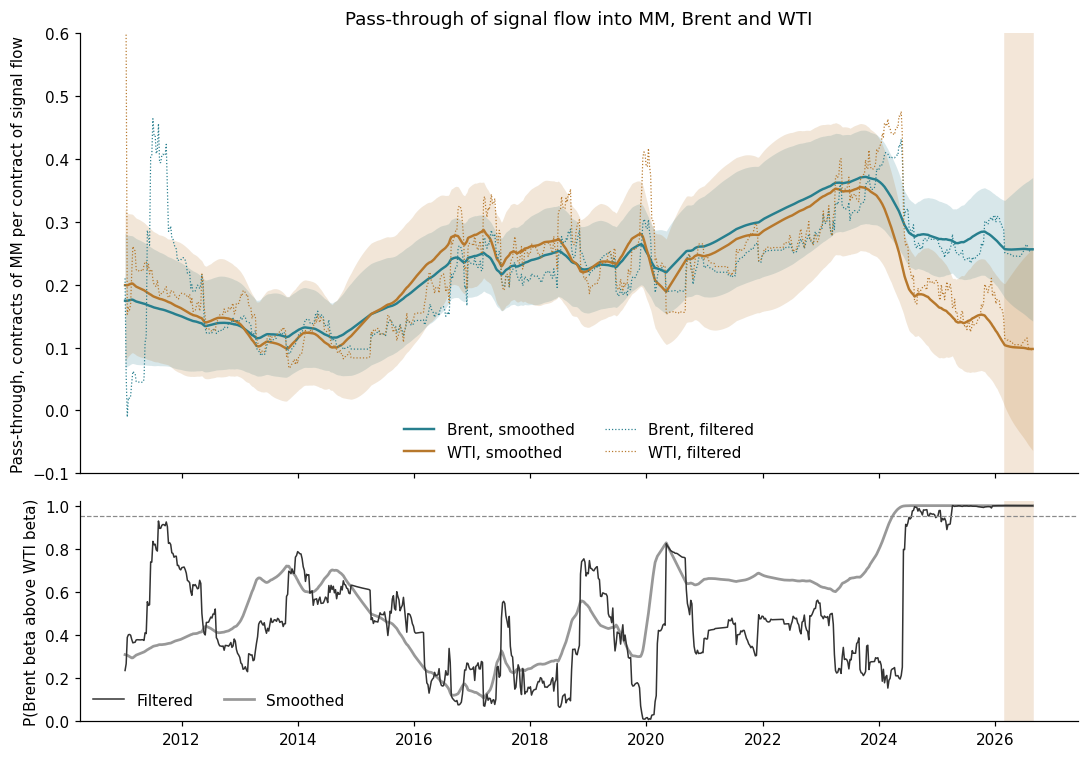

Share of 2012-2025 weeks with filtered tilt above 95%: 0.088
Filtered tilt stays above 95% from 2025-04-01; smoothed from 2024-04-02
Filtered tilt above 95% for 4+ weeks: ['2024-07-30 to 2024-12-17 (21 wks)', '2025-04-01 to 2026-08-25 (74 wks)']


In [4]:
paths = base["paths"]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, height_ratios=[2, 1])
for name, color, b, sd in [("Brent", BRENT, "beta_B_s", "sd_B_s"), ("WTI", WTI, "beta_W_s", "sd_W_s")]:
    axes[0].plot(paths.index, paths[b], color=color, lw=1.6, label=f"{name}, smoothed")
    axes[0].fill_between(paths.index, paths[b] - 1.96 * paths[sd], paths[b] + 1.96 * paths[sd], color=color, alpha=0.18, lw=0)
axes[0].plot(paths.index, paths["beta_B_f"], color=BRENT, lw=0.8, ls=":", label="Brent, filtered")
axes[0].plot(paths.index, paths["beta_W_f"], color=WTI, lw=0.8, ls=":", label="WTI, filtered")
axes[0].set(ylim=(-0.1, 0.6), ylabel="Pass-through, contracts of MM per contract of signal flow",
            title="Pass-through of signal flow into MM, Brent and WTI")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(paths.index, paths["tilt_f"], color="#333333", lw=1, label="Filtered")
axes[1].plot(paths.index, paths["tilt_s"], color="#333333", lw=1.8, alpha=0.5, label="Smoothed")
axes[1].axhline(0.95, color=ZERO_COLOR, lw=0.8, ls="--")
axes[1].set(ylabel="P(Brent beta above WTI beta)", ylim=(0, 1.02))
axes[1].legend(frameon=False, ncol=2, loc="lower left")
for ax in axes:
    ax.axvspan(WAR, END, color=WAR_SHADE, zorder=0)
fig.tight_layout()
fig.savefig(OUTPUT / "beta_paths.png", dpi=170)
plt.show()
paths.to_csv(OUTPUT / "brent_wti_paths.csv")

history = paths.loc["2012":"2025"]
print(f"Share of 2012-2025 weeks with filtered tilt above 95%: {(history['tilt_f'] > 0.95).mean():.3f}")
print(f"Filtered tilt stays above 95% from {kl.stays_above(paths['tilt_f'], 0.95):%Y-%m-%d}; "
      f"smoothed from {kl.stays_above(paths['tilt_s'], 0.95):%Y-%m-%d}")
above = paths["tilt_f"] > 0.95
episodes = paths[above].groupby((above != above.shift()).cumsum()[above]).apply(lambda g: (g.index[0], g.index[-1], len(g)), include_groups=False)
print("Filtered tilt above 95% for 4+ weeks:", [f"{a:%Y-%m-%d} to {b:%Y-%m-%d} ({n} wks)" for a, b, n in episodes if n >= 4])

**Step 5. Measure the changes.** From week $s$ to $T$, using the joint smoothed distribution, with $c=(1,-1)'$. Posterior sd: $\mathrm{sd}[c'(\beta_T-\beta_s)\mid\text{data}]$. Prior sd: $\sqrt{(T-s)\,c'Qc}$.

In [5]:
smoothed, Q_ = base["smoothed"], fit["Q"]
last, c = len(index) - 1, np.array([1.0, -1.0])
rows = []
for since in ["2019-12-31", "2022-12-27", "2023-12-26", "2024-12-31", "2025-12-30", "2026-02-24", "2026-04-28"]:
    i = index.searchsorted(pd.Timestamp(since), side="right") - 1
    cov = kl.joint_cov(smoothed["P_s"], smoothed["J"], i, last)
    V = smoothed["P_s"][i] + smoothed["P_s"][last] - cov - cov.T
    dB, dW = smoothed["a_s"][last] - smoothed["a_s"][i]
    rows.append({"Since": f"{index[i]:%Y-%m-%d}", "Change in Brent": dB, "95% half-width, Brent": 1.96 * np.sqrt(V[0, 0]),
                 "Change in WTI": dW, "95% half-width, WTI": 1.96 * np.sqrt(V[1, 1]), "Change in spread": dB - dW,
                 "Posterior sd": np.sqrt(c @ V @ c), "Prior sd": np.sqrt((last - i) * (c @ Q_ @ c))})
changes = pd.DataFrame(rows).set_index("Since")
changes.to_csv(OUTPUT / "spread_changes.csv")
print(f"End of sample: Brent {paths['beta_B_s'].iloc[-1]:.3f} (sd {paths['sd_B_s'].iloc[-1]:.3f}), "
      f"WTI {paths['beta_W_s'].iloc[-1]:.3f} (sd {paths['sd_W_s'].iloc[-1]:.3f})")
changes

End of sample: Brent 0.256 (sd 0.058), WTI 0.098 (sd 0.082)


,Change in Brent,"95% half-width, Brent",Change in WTI,"95% half-width, WTI",Change in spread,Posterior sd,Prior sd
Since,,,,,,,
2019-12-31,0.004,0.129,-0.160,0.180,0.164,0.058,0.126
2022-12-27,-0.093,0.140,-0.239,0.199,0.146,0.061,0.094
2023-12-26,-0.109,0.131,-0.241,0.188,0.132,0.056,0.080
2024-12-31,-0.018,0.121,-0.070,0.179,0.052,0.050,0.063
2025-12-30,-0.016,0.098,-0.032,0.151,0.015,0.038,0.040
2026-02-24,-0.002,0.087,-0.009,0.135,0.007,0.034,0.035
2026-04-28,0.000,0.071,-0.003,0.110,0.003,0.028,0.028


**What "time-varying" means.** A single regression gives one number for the whole sample. A time-varying measure gives a new number each week, so we can see how it rises or falls over the years. Here, each week's number covers the 52 weeks up to that week and answers one question: over the past year, how much of MM's position changes did the filter's trend-flow predictions account for?

**Step 6. Track the explained share.** Using the surprises $v^m_t$ from Step 2,

$$\text{share}^m_t = 1-\frac{\sum_{s=t-51}^{t}(v^m_s)^2}{\sum_{s=t-51}^{t}(y^m_s)^2},$$

and the same ratio over fixed windows. Each prediction uses that market's $\beta$ from before the week, so the share can be negative. $R$ and $Q$ are still full-sample. For comparison, window $R^2$ comes from a regression with its own intercept and slope, fitted on that window alone.

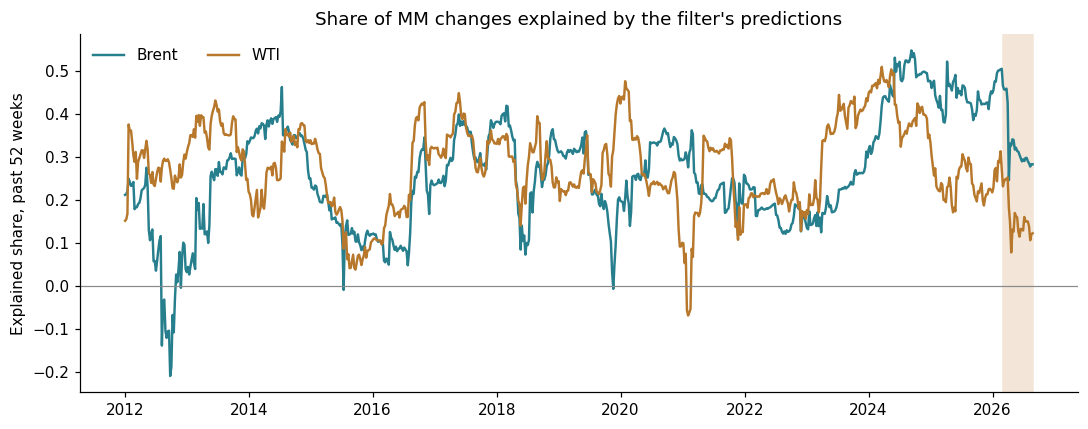

Brent, May-Aug 2026 window R² dropping any one week: 0.261 (2026-07-14) to 0.653 (2026-07-28)


Latest 52-week share, 2026-08-25: Brent 0.283, WTI 0.122


,"Brent, filter","WTI, filter","Brent, window R²","WTI, window R²"
2015-2019,0.267,0.318,0.275,0.343
2020-2023,0.263,0.250,0.270,0.267
2024,0.483,0.355,0.488,0.440
Pre-war year,0.505,0.270,0.514,0.343
Mar-Apr 2026,-0.480,-0.400,0.363,0.007
May-Aug 2026,0.184,-0.093,0.491,0.040


In [6]:
surprise = pd.DataFrame(base["filtered"]["v"], index=index, columns=["BRENT", "WTI"])
observed = pd.DataFrame({"BRENT": yB, "WTI": yW}, index=index).where(surprise.notna())
share = 1 - (surprise ** 2).rolling(52, min_periods=52).sum() / (observed ** 2).rolling(52, min_periods=52).sum()
share = share.loc["2012":]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(share.index, share["BRENT"], color=BRENT, lw=1.6, label="Brent")
ax.plot(share.index, share["WTI"], color=WTI, lw=1.6, label="WTI")
ax.axhline(0, color=ZERO_COLOR, lw=0.8)
ax.axvspan(WAR, END, color=WAR_SHADE, zorder=0)
ax.set(ylabel="Explained share, past 52 weeks", title="Share of MM changes explained by the filter's predictions")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "explained_share.png", dpi=170)
plt.show()
share.to_csv(OUTPUT / "explained_share.csv")

WINDOWS = {"2015-2019": ("2015-01-01", "2019-12-31"), "2020-2023": ("2020-01-01", "2023-12-31"), "2024": ("2024-01-01", "2024-12-31"),
           "Pre-war year": ("2025-03-04", "2026-02-24"), "Mar-Apr 2026": ("2026-03-03", "2026-04-30"), "May-Aug 2026": ("2026-05-01", "2026-08-31")}


def window_r2(market, start, end):
    return pd.concat([d_mm[market], flow[market]], axis=1).loc[start:end].dropna().corr().iloc[0, 1] ** 2


filter_share = pd.DataFrame({label: 1 - (surprise.loc[a:b] ** 2).sum() / (observed.loc[a:b] ** 2).sum() for label, (a, b) in WINDOWS.items()}).T
windows = filter_share.rename(columns={"BRENT": "Brent, filter", "WTI": "WTI, filter"})
windows["Brent, window R²"] = [window_r2("BRENT", a, b) for a, b in WINDOWS.values()]
windows["WTI, window R²"] = [window_r2("WTI", a, b) for a, b in WINDOWS.values()]
may_aug = pd.concat([d_mm["BRENT"], flow["BRENT"]], axis=1, keys=["y", "x"]).loc["2026-05-01":"2026-08-31"].dropna()
one_out = pd.Series({week: may_aug.drop(week).corr().iloc[0, 1] ** 2 for week in may_aug.index})
print(f"Brent, May-Aug 2026 window R² dropping any one week: {one_out.min():.3f} ({one_out.idxmin():%Y-%m-%d}) to {one_out.max():.3f} ({one_out.idxmax():%Y-%m-%d})")
print(f"Latest 52-week share, {share.index[-1]:%Y-%m-%d}: Brent {share['BRENT'].iloc[-1]:.3f}, WTI {share['WTI'].iloc[-1]:.3f}")
windows

**Note on 2012.** Brent's 52-week share reaches about −0.21 on 2012-09-25. The filter's $\beta_{t\mid t-1}$ was about 0.20–0.35 from late 2011 to May 2012, against a slope of about 0.10 fitted on that year alone ($R^2$ about 0.31), so its predictions overshot small MM flows.

## 3. Conclusion

- **The gap predates the war.** $P(\beta^B_t>\beta^W_t)$ stays above 0.95 from 2025-04-01 (filtered) and 2024-04-02 (smoothed), and the sample ends at $\beta^B=0.256$ and $\beta^W=0.098$. The two dates are a year apart, so the start is not pinned down.
- **WTI fell more.** Since 2023-12-26, $\Delta\beta^W=-0.241\pm0.188$ and $\Delta\beta^B=-0.109\pm0.131$, whose band spans zero. The spread widened by 0.132 (sd 0.056).
- **This does not show whether money moved from WTI to Brent.** $\hat\rho_Q=0.908$ means the two betas drift together over 2011–2026, but it is one number for the whole sample.
- **The filter says little about 2026.** Since 2026-02-24 the spread moved by 0.007, with a posterior sd of 0.034 against a prior sd of 0.035.
- **Explained share tells a different story from $\beta$ before the war.** Window $R^2$ in 2015–2019 and the pre-war year: WTI 0.343 and 0.343, Brent 0.275 and 0.514. So WTI's lower $\beta$ came without a lower explained share, while Brent's share rose.
- **WTI's explained share drops in the war.** May–Aug 2026 window $R^2$ ($n=17$): Brent 0.491, WTI 0.040. Brent's ranges from 0.261 to 0.653 when any one week is dropped. On the filter's own predictions: Brent 0.184, WTI −0.093. The 52-week share ends at 0.283 and 0.122.